# MHEDAS DL Lab 08: Mask R-CNN vs SAM 2

**Course 2026-2027 - Deep Learning Lab 08: Instance segmentation**

*NOTE that this session is mostly about interpretation (no high programming is needed)*.

Review of Mask R-CNN vs SAM 2:

| | **Mask R-CNN** (2017) | **SAM 2** (2024) |
|---|---|---|
| What it returns | Masks **with a class label and a score** (80 COCO classes) | Masks of "everything", **with no class label** |
| Trained to | Find objects of a fixed list of classes | Segment *any* region ("what is a segment?") ||

Task Deliverable: save as pdf and submit it to the task. Remember to put your names on the file!

## 1. Setup
*Change runtime type* to **T4 GPU**.

In [ ]:
!pip install -q ultralytics
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE -> change runtime type!")

GPU: Tesla T4


The following cells prepares everything for the rest of the notebook uses.

In [ ]:
# Imports
import time, io, os, requests, numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import dataclass
from PIL import Image
import skimage.data as skd
import torch
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2, MaskRCNN_ResNet50_FPN_V2_Weights
from torchvision.transforms.functional import to_tensor
from ultralytics import SAM
device = "cuda" if torch.cuda.is_available() else "cpu"

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
# Models

# for MaskRCNN, we load the torchvision version pretrained on COCO (80 classes)
# keeps low-confidence detections (0.05) so we can lower the threshold later
w = MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT
mrcnn = maskrcnn_resnet50_fpn_v2(weights=w, box_score_thresh=0.05).to(device).eval()
COCO = w.meta["categories"]

#We use SAM 2, as SAM 3 needs license
sam2 = SAM("sam2.1_b.pt")

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:01<00:00, 124MB/s]


In [ ]:
# Images

# downloads 3 everyday photos from the COCO dataset (cats, living_room, bedroom).
# creates two non-COCO images from scikit-image’s built-in data (coins and tissue).
# Each image is stored in a dictionary called IMAGES and also saved as a file, because SAM 2 reads images from disk.
os.makedirs("imgs", exist_ok=True)
IMAGES = {}
def _add(name, pil):
    IMAGES[name] = pil.convert("RGB"); IMAGES[name].save(f"imgs/{name}.jpg")
for name, i in [("cats", "000000039769"), ("living_room", "000000000139"), ("bedroom", "000000000632")]:
    try:
        r = requests.get(f"http://images.cocodataset.org/val2017/{i}.jpg", timeout=20); r.raise_for_status()
        _add(name, Image.open(io.BytesIO(r.content)))
    except Exception as e:
        print("could not load", name, e)
_add("coins", Image.fromarray(skd.coins()))                       # not a COCO class
_add("tissue", Image.fromarray(skd.immunohistochemistry()))       # stained tissue, not COCO


In [ ]:
#  helpers
@dataclass
class Inst:
    label: str
    score: float
    mask: np.ndarray
    box: tuple

TIMES, FAILURES, _cache, _last = {}, [], {}, {}
KINDS = ["missed object", "false positive", "merged instances", "split instance",
         "wrong class", "poor boundary", "no label / ambiguous", "other"]

def _sync():
    if device == "cuda": torch.cuda.synchronize()

def _box(m):
    ys, xs = np.where(m)
    return (xs.min(), ys.min(), xs.max(), ys.max()) if len(xs) else (0, 0, 0, 0)

# runs Mask R-CNN on an image and returns a list of instances, each with a label, a score and a mask
def run_maskrcnn(name):
    if ("m", name) not in _cache:
        x = to_tensor(IMAGES[name]).to(device)
        _sync(); t = time.perf_counter()
        with torch.no_grad(): out = mrcnn([x])[0]
        _sync(); TIMES["Mask R-CNN"] = time.perf_counter() - t
        masks = (out["masks"][:, 0] > 0.5).cpu().numpy()
        _cache[("m", name)] = [Inst(COCO[int(l)], float(s), m, tuple(b.tolist()))
                               for l, s, m, b in zip(out["labels"].cpu(), out["scores"].cpu(), masks, out["boxes"].cpu())]
    return _cache[("m", name)]

# runs SAM 2 in “segment everything” mode and returns its masks with no labels.
def run_sam2(name, max_masks=40):
    """SAM 2 'segment everything'. Tiny / giant masks are dropped to keep the picture readable."""
    if ("s", name) not in _cache:
        W, H = IMAGES[name].size
        _sync(); t = time.perf_counter()
        r = sam2(f"imgs/{name}.jpg", verbose=False)[0]
        _sync(); TIMES["SAM 2"] = time.perf_counter() - t
        data = r.masks.data.cpu().numpy() > 0.5
        try: conf = r.boxes.conf.cpu().numpy()
        except Exception: conf = np.ones(len(data))
        out = []
        for m, c in zip(data, conf):
            if m.shape != (H, W):
                m = np.array(Image.fromarray(m.astype(np.uint8) * 255).resize((W, H))) > 127
            frac = m.mean()
            if 0.0005 < frac < 0.6:
                out.append(Inst("segment", float(c), m, _box(m)))
        out.sort(key=lambda i: (-i.score, -i.mask.sum()))
        _cache[("s", name)] = out
    return _cache[("s", name)]

def _colors(n):
    cm = plt.get_cmap("tab20"); return [cm(i % 20)[:3] for i in range(n)]

def overlay(image, insts, ax, title, labels=True):
    out = np.asarray(image).astype(np.float32) / 255
    cols = _colors(len(insts))
    for inst, c in zip(insts, cols):
        out[inst.mask] = 0.5 * out[inst.mask] + 0.5 * np.array(c)
    ax.imshow(out); ax.set_title(title, fontsize=11); ax.axis("off")
    for k, (inst, c) in enumerate(zip(insts, cols)):
        txt = f"#{k} {inst.label} {inst.score:.2f}" if labels else f"#{k}"
        ax.text(inst.box[0], inst.box[1], txt, fontsize=7, color="white", va="bottom",
                bbox=dict(facecolor=c, alpha=0.85, pad=1, lw=0))

# shows the original, the Mask R-CNN result (with labels and scores) and the SAM 2 result side by side.
def show_both(name, thr_m=0.5, max_sam=40):
    """Original | Mask R-CNN (label + score) | SAM 2 (segment everything)."""
    img = IMAGES[name]
    M = sorted([i for i in run_maskrcnn(name) if i.score >= thr_m], key=lambda i: -i.score)
    S = run_sam2(name)[:max_sam]
    _last.update(name=name, M=M, S=S)
    fig, ax = plt.subplots(1, 3, figsize=(20, 7))
    ax[0].imshow(img); ax[0].set_title(name); ax[0].axis("off")
    overlay(img, M, ax[1], f"Mask R-CNN (score ≥ {thr_m}) -> {len(M)} instances")
    overlay(img, S, ax[2], f"SAM 2, segment everything -> {len(S)} masks", labels=False)
    plt.tight_layout(); plt.show()
    print(f"inference time: Mask R-CNN {TIMES['Mask R-CNN']:.2f}s | SAM 2 {TIMES['SAM 2']:.2f}s")

# builds a table. For each Mask R-CNN instance it finds the SAM 2 mask that overlaps it most and reports their IoU (1 = identical, 0 = no overlap).
def compare(name=None, thr_m=0.5, max_sam=40):
    """For every Mask R-CNN instance: the SAM 2 mask that overlaps it most, and their IoU (1 = identical)."""
    if name: _last.update(name=name,
        M=sorted([i for i in run_maskrcnn(name) if i.score >= thr_m], key=lambda i: -i.score), S=run_sam2(name)[:max_sam])
    M, S = _last["M"], _last["S"]
    rows = []
    if M and S:
        a = np.stack([i.mask.ravel() for i in M]).astype(np.float32)
        b = np.stack([i.mask.ravel() for i in S]).astype(np.float32)
        inter = a @ b.T
        iou = inter / np.maximum(a.sum(1)[:, None] + b.sum(1)[None] - inter, 1)
    for i, m in enumerate(M):
        j = int(iou[i].argmax()) if S else -1
        v = float(iou[i, j]) if S else 0.0
        rows.append(dict(MaskRCNN=f"#{i} {m.label}", score=round(m.score, 2),
                         best_SAM2_mask=f"#{j}" if v > 0 else "-", IoU=round(v, 2),
                         verdict="no SAM 2 match" if v == 0 else "agree" if v >= 0.75 else "partial" if v >= 0.5 else "disagree"))
    matched = {int(iou[i].argmax()) for i in range(len(M)) if S and iou[i].max() >= 0.5} if M and S else set()
    print(f"SAM 2 masks with no matching Mask R-CNN instance (IoU<0.5): {len(S) - len(matched)} of {len(S)}")
    return pd.DataFrame(rows).style.background_gradient(subset=["IoU"], cmap="RdYlGn", vmin=0, vmax=1)

# shows one pair of masks up close.
def zoom(i, j):
    """Zoom on Mask R-CNN #i vs SAM 2 #j from the last show_both/compare call."""
    img = IMAGES[_last["name"]]; m, s = _last["M"][i], _last["S"][j]
    x0, y0 = int(min(m.box[0], s.box[0])) - 10, int(min(m.box[1], s.box[1])) - 10
    x1, y1 = int(max(m.box[2], s.box[2])) + 10, int(max(m.box[3], s.box[3])) + 10
    x0, y0 = max(x0, 0), max(y0, 0)
    base = np.asarray(img)[y0:y1, x0:x1]; mm, ss = m.mask[y0:y1, x0:x1], s.mask[y0:y1, x0:x1]
    d = np.zeros(base.shape, np.float32); d[mm & ~ss] = [1, 0, 0]; d[ss & ~mm] = [0, .4, 1]; d[mm & ss] = [1, 1, 1]
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(base); ax[0].contour(mm, [0.5], colors="red"); ax[0].set_title(f"Mask R-CNN #{i} ({m.label})")
    ax[1].imshow(base); ax[1].contour(ss, [0.5], colors="deepskyblue"); ax[1].set_title(f"SAM 2 #{j}")
    ax[2].imshow(d); ax[2].set_title("red = Mask R-CNN only | blue = SAM 2 only | white = both")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

def log_failure(model, image, kind, note):
    assert model in ("Mask R-CNN", "SAM 2"), "model must be 'Mask R-CNN' or 'SAM 2'"
    assert kind in KINDS, f"kind must be one of {KINDS}"
    FAILURES.append(dict(model=model, image=image, kind=kind, note=note))
    return pd.DataFrame(FAILURES)

print("Ready.")

Ready.


## 2. Example and interpretation



Run the following cell. Each mask has a number `#k`; Mask R-CNN also prints its **class and confidence**.

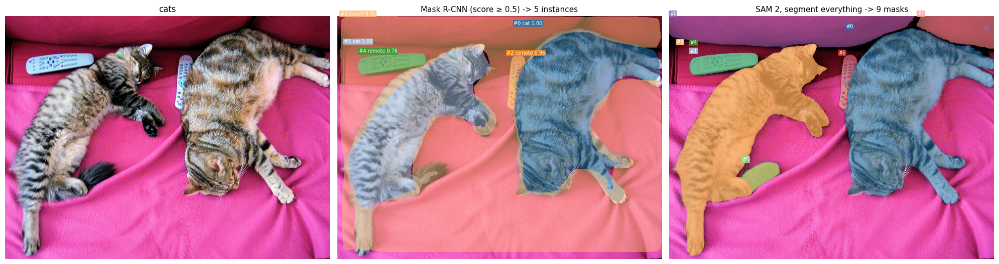

inference time: Mask R-CNN 2.05s | SAM 2 4.77s


In [ ]:
# Run Mask-RCNN and SAM on the 'cats' image and show both
show_both("cats")

### 2.1. How to interpret?

Try to answer these questions on the above images:

1. **Count & coverage** — what did each model find? What did only one find?
2. **Meaning** — does the model tell you *what* it is (label), or just *where* a region is?
3. **Granularity** — is a mask a whole object, a *part* of one (a cushion, an ear), or *background* (floor, wall)?
4. **Boundaries** — zoom in: do edges follow the object?
5. **Confidence** — are the scores believable? Anything with a high score that is wrong?



Now we measure agreement quantitatively. We will use `compare()` that pairs each Mask R-CNN instance with the SAM 2 mask that overlaps most. **IoU** = overlap/union (1 = identical, 0 = disjoint). Then `zoom(i, j)` shows the pair in detail.

In [ ]:
compare("cats")

SAM 2 masks with no matching Mask R-CNN instance (IoU<0.5): 5 of 9


,MaskRCNN,score,best_SAM2_mask,IoU,verdict
0,#0 cat,1.000000,#0,0.940000,agree
1,#1 cat,1.000000,#2,0.910000,agree
2,#2 remote,0.960000,#6,0.960000,agree
3,#3 couch,0.910000,#8,0.120000,disagree
4,#4 remote,0.780000,#4,0.970000,agree


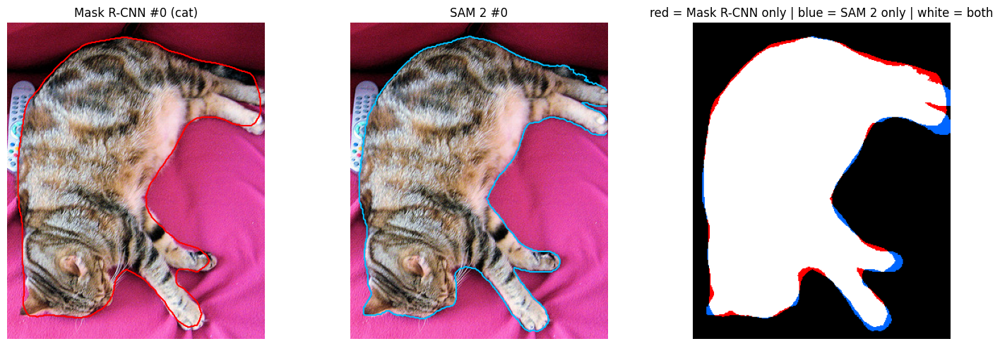

In [ ]:
zoom(0, 0)      # Mask R-CNN #0 vs SAM 2 #0. Change the numbers to inspect other pairs

**Q1:** Explain what you see and give a reasoned conclusion (<5 lines).

In the summary table, both models strongly agree on discrete foreground objects like the two cats and two remotes (IoU >= 0.91), but disagree on the background couch (IoU = 0.12), while SAM 2 also generates 5 unmatched masks.
The zoom(0, 0) visual confirms a near-identical segmentation for the first cat (IoU = 0.94), with only minor edge discrepancies around the paws and fur.
In conclusion, both models perform reliably and consistently on distinct foreground instances, whereas disagreements stem from background ambiguity and SAM 2's finer, class-agnostic over-segmentation.


## 3. Exercises



### 3.1 Everyday scenes
We will repeat the cats example with everyday scenes (living_room and bedroom, already available in our imgs folder)

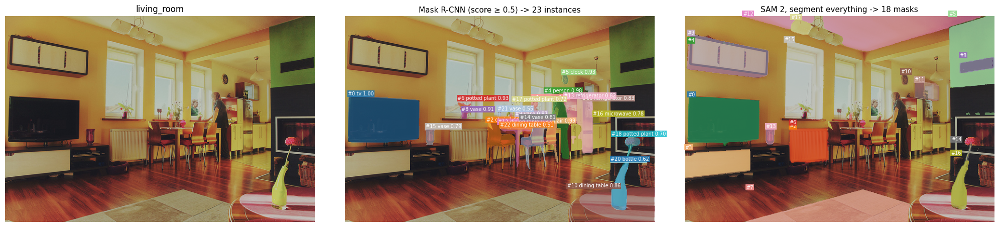

inference time: Mask R-CNN 0.29s | SAM 2 5.16s
SAM 2 masks with no matching Mask R-CNN instance (IoU<0.5): 13 of 18


,MaskRCNN,score,best_SAM2_mask,IoU,verdict
0,#0 tv,1.000000,#0,0.970000,agree
1,#1 chair,1.000000,-,0.000000,no SAM 2 match
2,#2 chair,1.000000,#6,0.010000,disagree
3,#3 chair,0.990000,-,0.000000,no SAM 2 match
4,#4 person,0.980000,-,0.000000,no SAM 2 match
5,#5 clock,0.930000,#10,0.850000,agree
6,#6 potted plant,0.930000,#15,0.010000,disagree
7,#7 person,0.910000,-,0.000000,no SAM 2 match
8,#8 vase,0.910000,#15,0.000000,disagree
9,#9 vase,0.870000,-,0.000000,no SAM 2 match


In [ ]:
# same sequence as before
show_both("living_room")
compare("living_room")

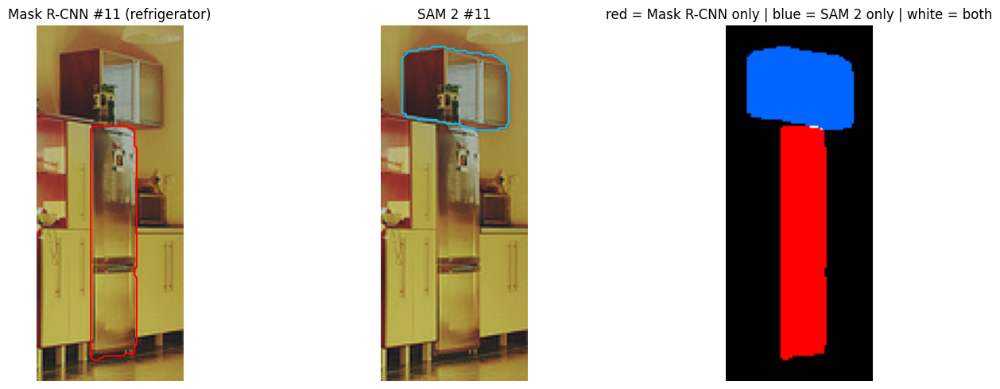

In [ ]:
zoom(11,11)

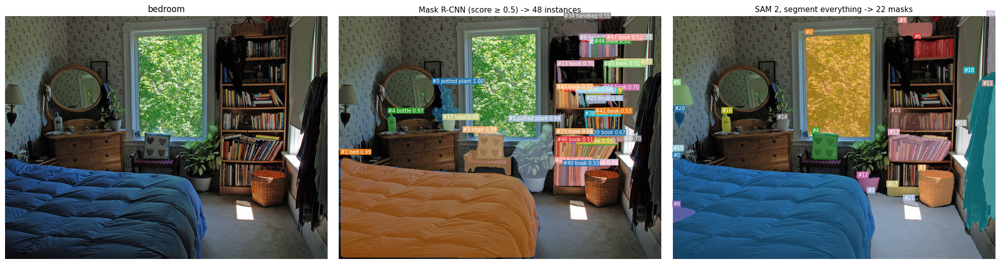

inference time: Mask R-CNN 0.29s | SAM 2 5.16s
SAM 2 masks with no matching Mask R-CNN instance (IoU<0.5): 15 of 22


,MaskRCNN,score,best_SAM2_mask,IoU,verdict
0,#0 potted plant,1.000000,#14,0.180000,disagree
1,#1 potted plant,0.990000,#12,0.150000,disagree
2,#2 bed,0.990000,#0,0.960000,agree
3,#3 chair,0.990000,#4,0.530000,partial
4,#4 bottle,0.970000,#16,0.850000,agree
5,#5 book,0.830000,-,0.000000,no SAM 2 match
6,#6 book,0.810000,#6,0.080000,disagree
7,#7 book,0.780000,#13,0.030000,disagree
8,#8 book,0.750000,#13,0.010000,disagree
9,#9 book,0.740000,#6,0.900000,agree


In [ ]:
show_both("bedroom")
compare("bedroom")

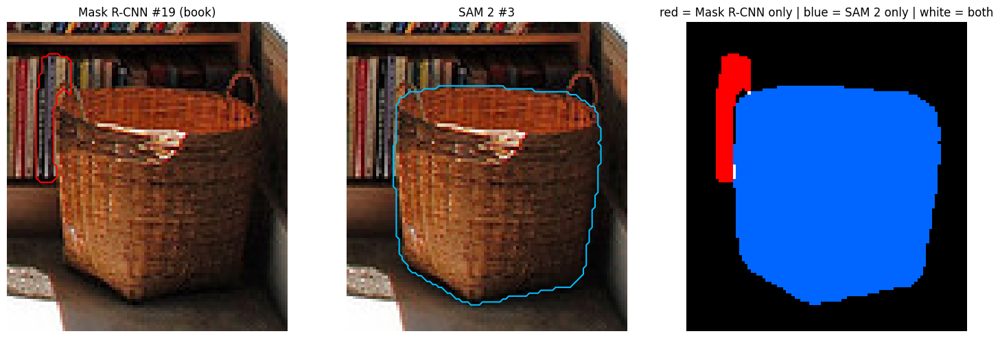

In [ ]:
zoom(19,3)

**Q2.** For each image, complete the following table:

| | living_room | bedroom |
|---|---|---|
| # Mask R-CNN instances / # SAM 2 masks | 23/18 | 48/22 |
| An object found by **both** (IoU?) | TV | Bed |
| An object found **only by Mask R-CNN** | Microwave | #5 book |
| A SAM 2 mask that is **not an object** (part / background)? | Ceiling | Window|
| Which model has the better boundaries? | SAM 2 | SAM 2|





**Q3.** Pick the pair with the **lowest IoU** among matched objects (use `zoom`). Why are they different: (a) one mask is wrong, (b) they cover different things (whole vs part), or (c) just boundary quality?



In both rooms, the pair with the lowest IoU (=0) among matched objects cover different things. In the living room, Mask R-CNN covers the refrigerator while SAM 2 covers the cabinet. In the bedroom, Mask R-CNN covers the books while SAM 2 covers the basket.

**Q4.** Mask R-CNN gives a score per object. What does the score tell you? Is there any object where a high score was wrong, or a low score was right? (Try `show_both("bedroom", thr_m=0.2)`.)

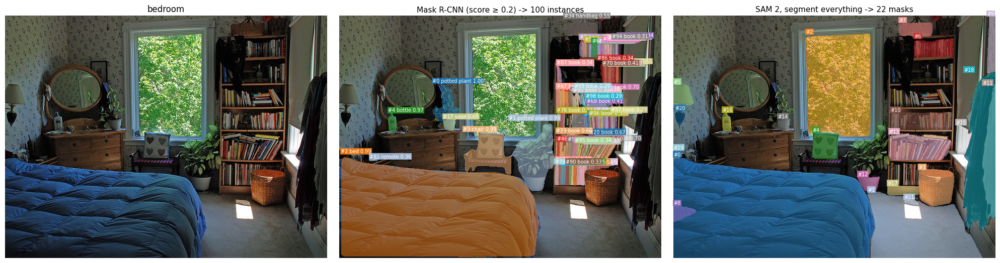

inference time: Mask R-CNN 0.29s | SAM 2 5.16s
SAM 2 masks with no matching Mask R-CNN instance (IoU<0.5): 14 of 22


,MaskRCNN,score,best_SAM2_mask,IoU,verdict
0,#0 potted plant,1.000000,#14,0.180000,disagree
1,#1 potted plant,0.990000,#12,0.150000,disagree
2,#2 bed,0.990000,#0,0.960000,agree
3,#3 chair,0.990000,#4,0.530000,partial
4,#4 bottle,0.970000,#16,0.850000,agree
5,#5 book,0.830000,-,0.000000,no SAM 2 match
6,#6 book,0.810000,#6,0.080000,disagree
7,#7 book,0.780000,#13,0.030000,disagree
8,#8 book,0.750000,#13,0.010000,disagree
9,#9 book,0.740000,#6,0.900000,agree


In [ ]:
show_both("bedroom", thr_m=0.2)
compare("bedroom", thr_m=0.2)

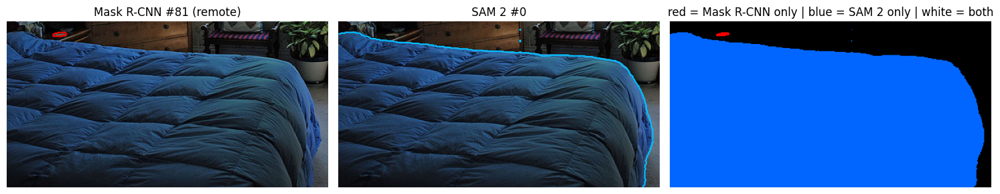

In [ ]:
zoom(81,0)

The score (ranging from 0.0 to 1.0) is the model's classification confidence, in other words, how certain Mask R-CNN is that a detected region belongs to a specific COCO object category (e.g., bed, chair, book).
- High Score, Wrong Prediction   
\#34 handbag (score = 0.55): In the top-right above the bookshelf, Mask R-CNN confidently labels a woven storage basket/box as a handbag.
- Low Score, Right Prediction   
Almost every newly revealed detection after lowering the confidence floor to 0.20 (such as #75 book at 0.38 with IoU = 0.20, or #91 book at 0.32 and #90 book at 0.33 visible on the shelves) is a genuine book on the bookcase that was previously hidden by the 0.50 threshold, showing that Mask R-CNN still accurately locates real objects even when its confidence score drops below 0.50.

### 3.2 Images the models were not made for

We'll study the behaviour of the models when using images of coins and tissue found elsewhere (i.e. not in the COCO set)

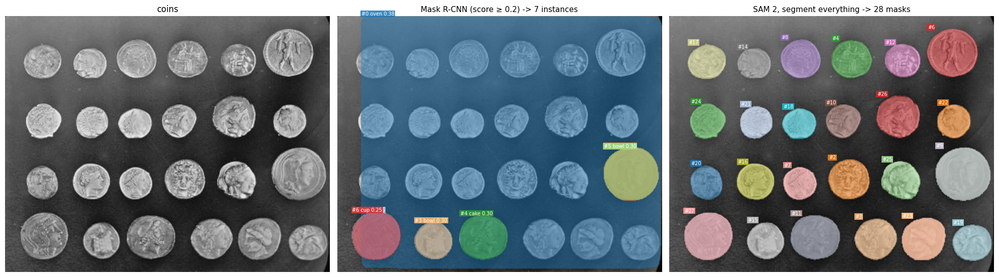

inference time: Mask R-CNN 0.22s | SAM 2 4.82s


In [ ]:
show_both("coins", thr_m=0.2)

**Q5.** count the coins by hand. What does Mask R-CNN return on `coins` and `tissue` (labels, number)? Why does it say that? And SAM 2: how many of its masks correspond to coins or cells, and what else does it segment?



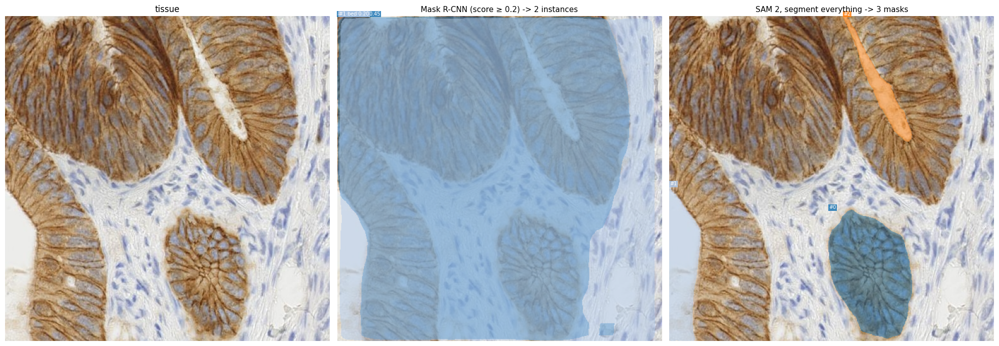

inference time: Mask R-CNN 0.17s | SAM 2 4.81s


In [ ]:
show_both("tissue", thr_m=0.2)

- There are 24 coins in total arranged in 4 rows of 6 coins each (6 + 6 + 6 + 6 = 24).

- What Mask R-CNN Returns & Why
  - On coins (7 instances at score >= 0.2): It fails to recognize "coins" and instead outputs household labels: oven (#0, covering almost the whole tray), bowl (#3, 0.30), cup (#4, 0.25), bowl (#5, 0.24), and vase (#6, 0.20).
  - On tissue (2 instances at score >= 0.2): It outputs 2 giant overlapping masks covering almost the entire histology slide, misclassifying the tissue texture as everyday objects like bed.

- Why does it say that?  
Mask R-CNN is a closed-set semantic detector trained exclusively on the 80 COCO categories (everyday photos of people, animals, furniture, food, and kitchenware). Because ancient coins and microscopy tissue are completely outside its training vocabulary, it is forced to map round shapes to bowls/cups and textured patterns to ovens or food, or miss them entirely.

- What SAM 2 Segments
  - On coins (28 masks total): 24 of the 28 masks correspond cleanly and accurately to all 24 individual coins. It also segments internal details/engravings on the faces of the coins and/or tiny background artifacts.
  - On tissue (3 masks total): 1 mask (the large blue mask in the bottom-right, #1) corresponds to an entire multicellular gland/crypt structure. It also segments the white lumen/cavity inside the top-right gland (the orange mask, #0) and a tiny dark cell nucleus/spot in the center connective tissue (#2).

  Because SAM 2 is class-agnostic and segments based purely on visual edges and contrast rather than object names, it transfers effortlessly to specialized domains like coins and microscopy where Mask R-CNN completely breaks down.


**Q6.** Suppose you need to *count and measure* nuclei in tissue. Which model gives you something usable out of the box, which would need extra work, and what extra work (think: labels, training, post-processing)?


Neither model works right away, though SAM 2 is closer because it does not rely on everyday object names.
- Out of the box: Mask R-CNN fails completely because it only knows 80 common objects (like cars and food) and has never seen cells. SAM 2 finds shapes based on visual edges and already caught one tiny nucleus, though it misses hundreds of others at its default zoom.
- Extra work for Mask R-CNN: We must manually outline thousands of nuclei on tissue images (labels) and retrain the model to recognize a new "nucleus" category.
- Extra work for SAM 2: We need no labels or training, just two adjustments: zoom in on smaller image tiles with a denser grid of prompt points so it spots tiny nuclei, and use post-processing rules (filtering by size, round shape, and dark purple color) to delete non-nucleus masks like glands and empty spaces.

### 3.3 Biomedical images


To see how our models behave with biomedical images, we'll use a small set of **public biomedical examples** (fluorescence nuclei, a retina photograph, kidney tissue, a brain MRI slice). Any image that fails to download is simply skipped.

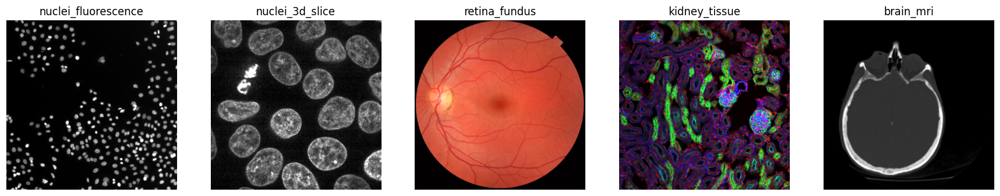

In [ ]:
# biomedical images download
!pip install -q pooch
def _u8(a):
    a = np.asarray(a).astype(np.float32); lo, hi = np.percentile(a, (1, 99.5))
    return (np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1) * 255).astype(np.uint8)

BIO = []
def _try(name, fn):
    try:
        im = Image.fromarray(_u8(fn())).convert("RGB"); im.thumbnail((1024, 1024))
        _add(name, im); BIO.append(name)
    except Exception as e:
        print("could not load", name, "-", str(e)[:80])

_try("nuclei_fluorescence", lambda: skd.human_mitosis())
_try("nuclei_3d_slice",     lambda: skd.cells3d()[30, 1])
_try("retina_fundus",       lambda: skd.retina())
_try("kidney_tissue",       lambda: skd.kidney()[8])
_try("brain_mri",           lambda: skd.brain()[5])

fig, ax = plt.subplots(1, max(len(BIO), 2), figsize=(4 * max(len(BIO), 2), 4))
for a, n in zip(np.ravel(ax), BIO):
    a.imshow(IMAGES[n]); a.set_title(n); a.axis("off")
plt.show()


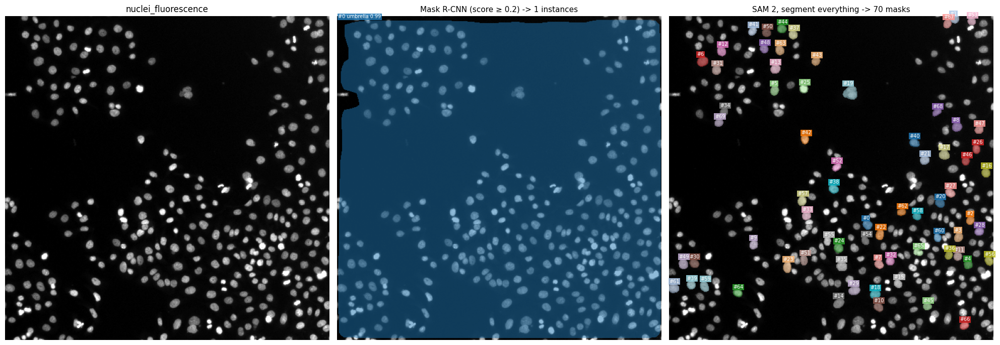

inference time: Mask R-CNN 0.18s | SAM 2 4.87s
SAM 2 masks with no matching Mask R-CNN instance (IoU<0.5): 70 of 70


,MaskRCNN,score,best_SAM2_mask,IoU,verdict
0,#0 umbrella,0.990000,#19,0.000000,disagree


In [ ]:

show_both("nuclei_fluorescence", thr_m=0.2, max_sam=80)     # SAM 2 shows up to 80 masks here
compare("nuclei_fluorescence", thr_m=0.2, max_sam=80)


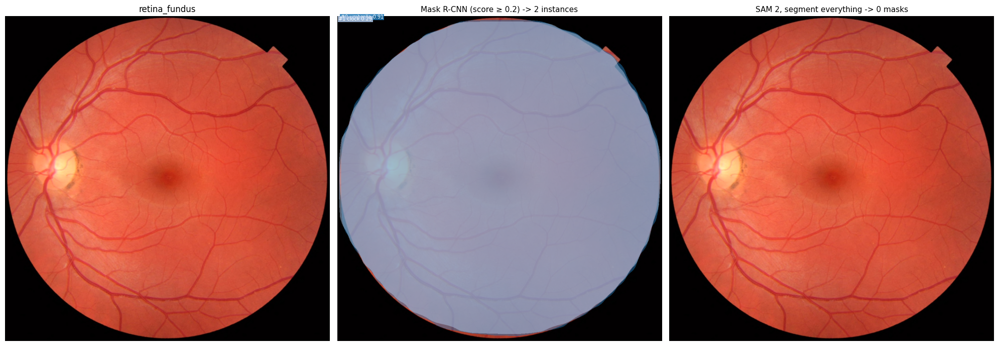

inference time: Mask R-CNN 0.17s | SAM 2 5.05s


In [ ]:

# pick another image: nuclei_3d_slice, retina_fundus, kidney_tissue or brain_mri
show_both("retina_fundus", thr_m=0.2, max_sam=40)



**Q7.** For the two (or more) biomedical images you ran, what does each model return? Is any mask biologically or clinically meaningful (a nucleus, the optic disc, a vessel, a lesion), or are they just regions of similar intensity? Which structures does SAM 2 miss or merge, and what do image properties (grayscale, contrast, scale, crowding) have to do with it? Could you *count* the nuclei with either model?



1. What each model returns
- nuclei_fluorescence (cells):
	- Mask R-CNN: Returns 1 giant mask covering the whole image and falsely labels it an umbrella (0.95 score).
	- SAM 2: Returns 70 small masks, each neatly outlining an individual cell nucleus.
- retina_fundus (eye scan):
	- Mask R-CNN: Returns 2 giant overlapping masks covering the entire round eye scan (treating the whole circle like an everyday round object).
	- SAM 2: Returns 0 masks (completely blank).

2. Are any masks biologically meaningful?
- In nuclei_fluorescence: Yes—SAM 2's 70 masks correspond to real individual nuclei. However, SAM 2 doesn't actually understand biology; it only found them because they appear as bright white blobs with sharp edges.
- In retina_fundus: No. Neither model detects clinically important structures like the optic disc (bright yellow spot), macula (dark center), or blood vessels. Mask R-CNN just segments the outer circular border of the photo.

3. What SAM 2 misses/merges & why image properties matter
- Contrast & Grayscale: Even without color, the high contrast in the grayscale nuclei image (bright white cells on a pure black background) gives SAM 2 sharp boundaries to lock onto. In the retina scan, the blood vessels and optic disc have low, blurry contrast against the orange-red background, so SAM 2 misses everything (0 masks).
- Scale & Crowding: Because nuclei are tiny (small scale) and packed tightly together (crowding), SAM 2's default grid of starting points misses over half of the cells and occasionally merges touching nuclei into a single mask.

4. Could you count the nuclei with either model?
- Mask R-CNN: No—it only outputs 1 big mask.
- SAM 2: Not accurately out of the box—it counts 70, which is a great start, but misses dozens of unmasked nuclei. To get a true count, we would need to zoom into smaller image tiles or increase the density of SAM 2's prompt grid.


## 4. Conclusions


**Q8.** Write your own conclusions (<5 lines)

Mask R-CNN is fast (\~0.2s) and provides clear semantic labels for everyday COCO objects, but fails completely on specialized domains like coins and biomedical scans without custom retraining. SAM 2 is slower (\~5s) and lacks object names, yet produces much sharper boundaries and transfers zero-shot to unseen domains whenever clear, high-contrast edges exist. However, SAM 2 still misses low-contrast or crowded structures and requires heavy filtering or dense prompting to isolate targets from background clutter. Ultimately, we should use Mask R-CNN for fast classification within known categories, and SAM 2 for precise, general-purpose segmentation on novel images.
